# Bring your own encoder: the Fisher metric J(x)

* **Goal**: take any fitted PyTorch model of neural responses, check that it meets the encoder contract, and compute the leading eigenvectors of its Fisher information metric J(x) for an image.
* **Steps**: (1) define the encoder, (2) `validate_encoder` checks the contract (rules R1-R9), (3) `compute_fisher` returns the top eigenpairs of J(x).
* **Needs**: `pip install multigeom` only (`matplotlib` for the last plot). A toy encoder is used so that the notebook runs in seconds on a CPU; replace it with your fitted model.
* **Execution time**: about 1 s on a CPU.

## 1. Your encoder

The encoder maps an image batch `[B, 1, 64, 64]` with values in `[-1, 1]` to responses `[B, N]`. It must be deterministic in eval mode and differentiable with respect to its input. Responses of order 1 match the default observation noise.

In [4]:
import torch
import torch.nn as nn
import multigeom

N_NEURONS = 20                                   # number of recorded neurons
SIGMA = 0.22                                     # observation noise of the responses


class MyEncoder(nn.Module):
    """A fitted model: here a random linear-nonlinear model standing in for yours."""

    def __init__(self, n_neurons=N_NEURONS):
        super().__init__()
        torch.manual_seed(0)
        self.n_neurons = n_neurons
        self.linear = nn.Linear(64 * 64, n_neurons)
        with torch.no_grad():
            self.linear.weight.mul_(3.0 / 64)    # keeps the responses of order 1

    def forward(self, x):
        return torch.tanh(self.linear(x.flatten(1)))


encoder = MyEncoder()

## 2. Check the contract

`validate_encoder` runs a few forward and backward passes on random images. It raises `EncoderContractError`, naming the rule and what to change, at the first violation; softer problems come back as warnings.

In [5]:
report = multigeom.validate_encoder(encoder, sigma=SIGMA)
print("neurons:", report.n_neurons, "| response std:", round(report.response_std, 3))
print("warnings:", report.warnings or "none")

neurons: 20 | response std: 0.117
warnings: none


## 3. Compute J(x)

`J(x) = J_f(x)^T J_f(x) / sigma^2`, where `J_f` is the Jacobian of the responses with respect to the pixels. `compute_fisher` returns its top eigenvalues and eigenvectors (each eigenvector is a 64 x 64 image, flattened).

In [6]:
torch.manual_seed(1)
x = torch.rand(1, 1, 64, 64) * 2 - 1             # replace by your image, scaled to [-1, 1]

fisher = multigeom.compute_fisher(image=x, encoder=encoder, sigma=SIGMA, top_k=10)
print("eigenvalues:", fisher.eigenvalues[:5].numpy().round(1))
print("eigenvectors:", tuple(fisher.eigenvectors.shape))

eigenvalues: [0. 0. 0. 0. 0.]
eigenvectors: (10, 4096)


## 4. Look at the leading eigenvectors

The leading eigenvectors are the image directions to which the model's responses are most sensitive.

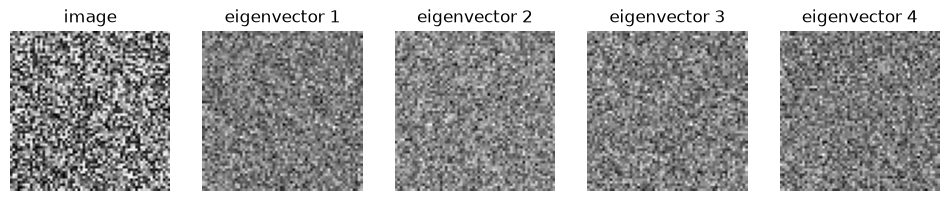

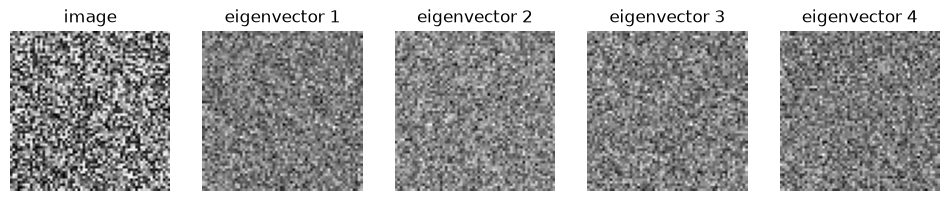

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(12, 2.8))
axes[0].imshow(x[0, 0], cmap="gray", vmin=-1, vmax=1)
axes[0].set_title("image")
for i, ax in enumerate(axes[1:]):
    ax.imshow(fisher.eigenvectors[i].reshape(64, 64), cmap="gray")
    ax.set_title(f"eigenvector {i + 1}")
for ax in axes:
    ax.axis("off")
fig